## Simulation

In [1]:
from oreABBR import *; import ORE as oe; import oreUTIL as ou
params  = oe.Parameters()  ; params.fromFile('Input/ore.xml')
mainOBJ = oe.OREApp(params); mainOBJ.run() ;ou.chkERR(mainOBJ)
asofDT = mainOBJ.getInputs().asof() ; print('asof:',asofDT)
mainOBJ.getReportNames()

Run time:0.09 sec, Errors:0
asof: August 19th, 2022


('curves',
 'dividends',
 'fixings',
 'marketdata',
 'npv',
 'pricingstats',
 'runtimes',
 'todaysmarketcalibration',
 'todaysmarketcalibration_cashflows')

In [2]:
# scenariodata gzip読み込み  comment='#':OREのヘッダコメントをスキップ
dfSD = pd.read_csv('Output/senaData.csv.gz',comment='#',header=None)
dfSD.columns = ['nDate','nSamp','ky','val']        ; print('dfSD:\n',dfSD)
dfKy0 = dfSD[dfSD.ky == 0]                         ; print('dfKy0:\n',dfKy0)

dfSD:
    nDate  nSamp  ky       val
0      1      0   0 -0.001451
1      1      0   1  0.999203
2      2      0   0  0.018113
3      2      0   1  1.018221
4      3      0   0  0.022094
5      3      0   1  1.033800
dfKy0:
    nDate  nSamp  ky       val
0      1      0   0 -0.001451
2      2      0   0  0.018113
4      3      0   0  0.022094


In [3]:
# cube gzip読み込み
dfCB = pd.read_csv("Output/cube.csv.gz",comment="#",header=None)
dfCB.columns  = ["ID", "nDate", "nSamp", "nDpth", "val"]; print('dfCB:\n',dfCB)

dfCB:
    ID  nDate  nSamp  nDpth          val
0   0      0      0      0 -230413.2660
1   0      1      0      0 -257715.7030
2   0      2      0      0   27613.9629
3   0      3      0      0   99002.8047


In [4]:
print( mainOBJ.getSupportedAnalyticTypes(), '\n' )
# Tonar fixing data
anaOBJ= mainOBJ.getAnalytic('XVA')    ; mktOBJ = anaOBJ.getMarket()
tnIX  = mktOBJ.iborIndex('JPY-TONAR') ; tnFix  = tnIX.fixing(asofDT)
print(asofDT.ISO(), f'Tonar fixing:{tnFix:.4%}')

('CASHFLOW', 'CASHFLOWNPV', 'EXPOSURE', 'NPV', 'PFE', 'SENSITIVITY', 'XVA') 

2022-08-19 Tonar fixing:-0.0090%


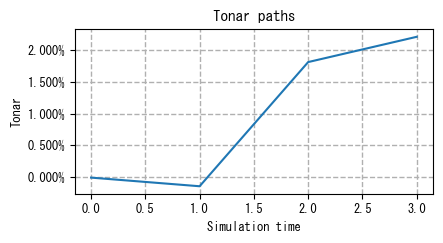

In [5]:
# Tonar path plot
_,ax = plt.subplots()
for ss in dfKy0.nSamp.unique()[:10]:
	dfPT = dfKy0[dfKy0.nSamp == ss]
	ax.plot(np.r_[0, dfPT.nDate], np.r_[tnFix, dfPT.val])
ax.set(xlabel='Simulation time', ylabel='Tonar')  ; ax.set_title('Tonar paths')
yPct(ax); gdShow(ax)

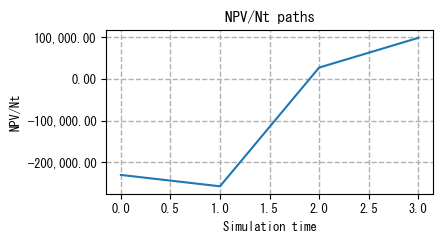

In [6]:
# NPV/Nt path plot
val0 = dfCB.val.iloc[0];  dfCB1 = dfCB[dfCB.nDate!=0];  _,ax = plt.subplots()
for ss in dfCB1.nSamp.unique()[:10]:
	dfPT = dfCB1[dfCB1.nSamp == ss]
	ax.plot(np.r_[0, dfPT.nDate], np.r_[val0, dfPT.val])
ax.set(xlabel='Simulation time', ylabel='NPV/Nt') ; ax.set_title('NPV/Nt paths')
yFlt(ax); gdShow(ax)

**データフレームの[ ]の役割**

| 書き方              | 意味               | 推奨度      |
| ---------------- | ---------------- | -------- |
| `dfSD.loc[mask]` | `.loc` によるラベル指定  | 高い（推奨）   |
| `dfSD[mask]`     | `[]` 演算子による行フィルタ | 動くが意味が曖昧 |

In [7]:
dfSD[['nDate', 'val']]  # 複数列を取り出す

,nDate,val
0,1,-0.001451
1,1,0.999203
2,2,0.018113
3,2,1.018221
4,3,0.022094
5,3,1.033800


In [8]:
dfSD[dfSD.ky == 0]  # 行をフィルタ

,nDate,nSamp,ky,val
0,1,0,0,-0.001451
2,2,0,0,0.018113
4,3,0,0,0.022094


In [9]:
dfSD[dfSD.ky == 0][['nDate', 'val']]  # 行をフィルタ後 複数列の取り出し

,nDate,val
0,1,-0.001451
2,2,0.018113
4,3,0.022094


In [10]:
dfSD.loc[dfSD.ky == 0]  #.locは「行・列の指定」を明示
                        # 行ラベルをこのブール配列で選ぶという意味

,nDate,nSamp,ky,val
0,1,0,0,-0.001451
2,2,0,0,0.018113
4,3,0,0,0.022094


In [11]:
dfSD.loc[dfSD.ky == 0, ['nDate', 'val']] #列の指定を追加

,nDate,val
0,1,-0.001451
2,2,0.018113
4,3,0.022094


In [12]:
dfSD.loc[:, ['nDate', 'val']] #列のみの指定

,nDate,val
0,1,-0.001451
1,1,0.999203
2,2,0.018113
3,2,1.018221
4,3,0.022094
5,3,1.033800
